# Week 8, Tuesday

## Reminders

Please schedule to meet with Luke (see Luke's Canvas Announcement) during this week, in anticipation of the Final Project Preparation assignment due Friday.

It's fine to use this meeting to discuss your ideas with Luke, or to ask Luke to help you come up with ideas.

Luke and I will try to have the midterms graded and returned next week.

Goal: meet some aspects of gradient descent. This helps us find weights, and baiases in neural newtowrk. 

Today: use gradiaent descent for linear regression.

For NNs, no exact formula for weights + biases.

Goal today: seek god slope and y-int for weight and bias in Linear Regression.

What do I mean by "best" weight and bias in Linear Regression?

We choose MSE for our loss function and "best" in this context means "minimum" MSE 

Minimize: L = 1/n * [(w * x_0 + b - y_0)^2 + . . . + (w * x_(n-1) + b - y_(n-1))^2]

what variables (w,b) minimize L? Use gradient descent

Idea of gradient descent?
We have a function like L(w,b) that we want to minimuze. Fact from calculus, if L is differentible, then the gradient descent points in the direction of fastest increase of L 

Compute gradient use partial derivatives

L_w = delta L / delta w = 1/n sum of (2 * (w * x_i + b - y_i) * x_i)

L_b = delta L / delta w = 1/n sum of (2 * (w * x_i + b - y_1) * 1)

## Gradient Descent for one-variable Linear Regression

Our medium-term goal is to see how to use Gradient Descent to seek effective weights and biases in a Neural Network.  Before that, today, we will see Gradient Descent in a simpler setting, for Linear Regression in the setting with just one predictor.  For Linear Regression, there are alternatives to Gradient Descent, related to the Normal Equation which provides an explicit solution for "the best slope and y-intercept".  In the context of Neural Networks, there is no explicit solution in general, so a variant of Gradient Descent is typically used.

**Starting question**: What do we mean by "the best slope and y-intercept"?

In [1]:
from sklearn.datasets import make_regression
from matplotlib import pyplot as plt

In [13]:
n = 100
x, y, coef = make_regression(n_samples=100, n_features=1, random_state=0, noise = 10, bias = -5, coef = True)
x = x.reshape(-1) # to avoid broadcasting issues below

In [ ]:
coef # slope

array(42.38550486)

True values are w = 42.385, b = -5

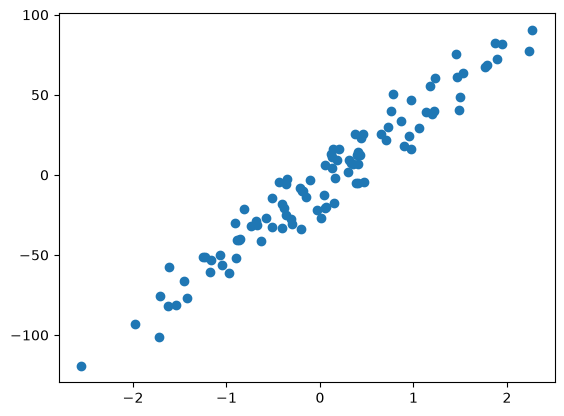

In [10]:
fig, ax = plt.subplots()
ax.scatter(x, y);

In [12]:
# starting values
w = 3
b = 10

In [14]:
((w * x + b - y)*x).shape

(100,)

In [17]:
# manually define partial derivtives of the MSE loss function with respect to w
def Lw(w, b, x, y):
    return (2 * (w * x + b - y) * x).mean()

In [18]:
def Lb(w, b, x, y):
    return (2 * (w * x + b - y) * 1).mean()

In [23]:
learn_rate = 0.01
epochs = 100000 # repeat this many times

for i in range(epochs):
    grad_w = Lw(w, b, x, y)
    grad_b = Lb(w, b, x, y)
    w = w - learn_rate * grad_w
    b = b - learn_rate * grad_b

In [24]:
print( w, b)

42.619430291366776 -5.814181827030694


In [26]:
from sklearn.linear_model import LinearRegression

In [27]:
reg = LinearRegression()
reg.fit(x.reshape(-1, 1), y)
reg.coef_

array([42.61943029])

In [28]:
reg.intercept_

np.float64(-5.814181827030725)

In [ ]:
# MSE loss function
def L(w, b, x, y):
    return((w * x + b - y)**2). mean()

In [30]:
L(42.6194, -5.814, x, y)

np.float64(114.17148620153247)

In [ ]:
# true values give a worse loss
L(43.385, -5, x, y)

np.float64(115.50640581677517)

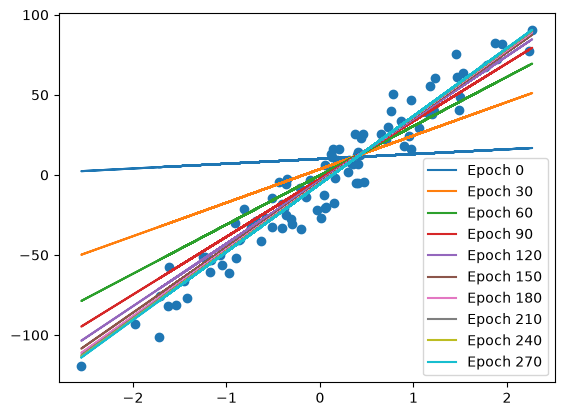

In [35]:
w = 3
b = 10

fig, ax = plt.subplots()
ax.scatter(x, y)

learn_rate = 0.01
epochs = 300 # repeat this many times

for i in range(epochs):
    if i%30 == 0:
        ax.plot(x, w * x + b, label = f"Epoch {i}")
    grad_w = Lw(w, b, x, y)
    grad_b = Lb(w, b, x, y)
    w = w - learn_rate * grad_w
    b = b - learn_rate * grad_b

ax.legend()

Updates for next time:
* Rather than using all data at each update, we will divide the data into "mini=batches"
* Increase the number of predictors

For nueral networks:
* Need to be more careful with sour tarting values and/or try multiple starting values
* Partial derivatives will take much more strategy to compute; the process is called "back-propagation"